In [1]:
# ============================================================
# PREDICTIVE MODELING — NCAA Tournament Upset Prediction
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
print("✅ All libraries loaded.")

✅ All libraries loaded.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab Notebooks/DATA6999/model_ready_r64.csv'
df = pd.read_csv(file_path)

print(f"✅ Data loaded: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"   Upset distribution: {df['UPSET'].value_counts().to_dict()}")
print(f"   Upset rate: {df['UPSET'].mean():.1%}")

Mounted at /content/drive
✅ Data loaded: 578 rows, 55 columns
   Upset distribution: {0: 425, 1: 153}
   Upset rate: 26.5%


In [3]:
# ============================================================
# CELL 3 - FEATURE ENGINEERING (LEAKAGE-FREE)
# ============================================================
# NOTE: Original DIFF_ columns (Winner - Loser) contained data leakage.
# Recomputed as Favorite - Cinderella (by seed) to eliminate outcome
# information from features. See professor feedback 6/30/2026.
#
# Additionally, reduced from 16 features to 5 selected features
# to address multicollinearity and overfitting with small sample size.
# ============================================================

# Identify favorite (lower seed number) and cinderella (higher seed number)
df['FAV_SEED'] = df[['WINNER_SEED', 'LOSER_SEED']].min(axis=1)
df['CIN_SEED'] = df[['WINNER_SEED', 'LOSER_SEED']].max(axis=1)

# Raw stat columns (without the W_ or L_ prefix)
stat_names = ['KADJ EM', 'KADJ O', 'KADJ D', 'BADJ EM', 'BARTHAG',
              'EFG%', 'EFG%D', 'TOV%', 'TOV%D', 'OREB%', 'DREB%',
              'EXP', 'TALENT', 'WIN%', 'WAB', 'ELITE SOS']

# For each stat, compute FAVORITE - CINDERELLA
for stat in stat_names:
    fav_val = df.apply(
        lambda r: r[f'W_{stat}'] if r['WINNER_SEED'] <= r['LOSER_SEED']
                  else r[f'L_{stat}'], axis=1)
    cin_val = df.apply(
        lambda r: r[f'L_{stat}'] if r['WINNER_SEED'] <= r['LOSER_SEED']
                  else r[f'W_{stat}'], axis=1)
    df[f'FIX_DIFF_{stat}'] = fav_val - cin_val  # Positive = favorite is better

# Seed diff (always positive: cinderella seed minus favorite seed)
df['FIX_SEED_DIFF'] = df['CIN_SEED'] - df['FAV_SEED']

# Selected features: Top predictors with low multicollinearity
# - WAB: top feature importance in RF, measures quality of wins
# - KADJ EM: overall efficiency (the "master metric" from KenPom)
# - EFG%: shooting efficiency (component skill, independent dimension)
# - TOV%: turnover rate (different dimension of play)
# - OREB%: offensive rebounding (another independent dimension)
selected_features = ['FIX_DIFF_WAB', 'FIX_DIFF_KADJ EM', 'FIX_DIFF_EFG%',
                     'FIX_DIFF_TOV%', 'FIX_DIFF_OREB%']

X_full = df[selected_features]
X_base = df[['FIX_SEED_DIFF']]
y = df['UPSET']

fix_diff_cols = selected_features

print("=" * 60)
print("LEAKAGE-FREE FEATURE ENGINEERING")
print("=" * 60)
print(f"Features recomputed as FAVORITE - CINDERELLA (by seed)")
print(f"Full feature set ({len(selected_features)} selected variables):")
for f in selected_features:
    print(f"  - {f}")
print(f"\nBaseline feature set: FIX_SEED_DIFF only")
print()

# Sanity check: Both means should be positive
# In non-upset games, favorite is better AND won (positive diff, expected)
# In upset games, favorite is STILL better on paper but lost (positive diff, upset)
non_upset_mean = df.loc[df['UPSET']==0, 'FIX_DIFF_KADJ EM'].mean()
upset_mean = df.loc[df['UPSET']==1, 'FIX_DIFF_KADJ EM'].mean()
print(f"Sanity Check (FIX_DIFF_KADJ EM):")
print(f"  Non-upset games (fav won):  mean = {non_upset_mean:+.2f} (should be positive)")
print(f"  Upset games (cin won):      mean = {upset_mean:+.2f} (should ALSO be positive)")
print(f"  Both positive? {'YES - no leakage' if non_upset_mean > 0 and upset_mean > 0 else 'NO - check logic'}")
print()
print("✅ Features ready for modeling.")

LEAKAGE-FREE FEATURE ENGINEERING
Features recomputed as FAVORITE - CINDERELLA (by seed)
Full feature set (5 selected variables):
  - FIX_DIFF_WAB
  - FIX_DIFF_KADJ EM
  - FIX_DIFF_EFG%
  - FIX_DIFF_TOV%
  - FIX_DIFF_OREB%

Baseline feature set: FIX_SEED_DIFF only

Sanity Check (FIX_DIFF_KADJ EM):
  Non-upset games (fav won):  mean = +15.42 (should be positive)
  Upset games (cin won):      mean = +5.55 (should ALSO be positive)
  Both positive? YES - no leakage

✅ Features ready for modeling.


In [4]:
# ============================================================
# CELL 4 - TRAIN/TEST SPLIT (STRATIFIED)
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_full_train, X_full_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.25, random_state=42, stratify=y)

X_base_train, X_base_test, _, _ = train_test_split(
    X_base, y, test_size=0.25, random_state=42, stratify=y)

scaler_full = StandardScaler()
scaler_base = StandardScaler()

print(f"Training set: {len(y_train)} samples")
print(f"  No Upset: {(y_train==0).sum()} ({(y_train==0).mean():.1%})")
print(f"  Upset:    {(y_train==1).sum()} ({(y_train==1).mean():.1%})")
print(f"\nTest set: {len(y_test)} samples")
print(f"  No Upset: {(y_test==0).sum()} ({(y_test==0).mean():.1%})")
print(f"  Upset:    {(y_test==1).sum()} ({(y_test==1).mean():.1%})")

Training set: 433 samples
  No Upset: 318 (73.4%)
  Upset:    115 (26.6%)

Test set: 145 samples
  No Upset: 107 (73.8%)
  Upset:    38 (26.2%)


In [5]:
# ============================================================
# CELL 4b - SMOTE: Handling Class Imbalance
# ============================================================
from imblearn.over_sampling import SMOTE

print("=== BEFORE SMOTE ===")
print(f"  Training set: {len(y_train)} samples")
print(f"  No Upset (0): {(y_train==0).sum()}  ({(y_train==0).mean():.1%})")
print(f"  Upset (1):    {(y_train==1).sum()}  ({(y_train==1).mean():.1%})")

sm = SMOTE(random_state=42)

X_full_train_sm, y_train_sm = sm.fit_resample(X_full_train, y_train)
X_base_train_sm, _ = sm.fit_resample(X_base_train, y_train)

X_full_train_sm_sc = scaler_full.fit_transform(X_full_train_sm)
X_base_train_sm_sc = scaler_base.fit_transform(X_base_train_sm)

X_full_test_sc = scaler_full.transform(X_full_test)
X_base_test_sc = scaler_base.transform(X_base_test)

print("\n=== AFTER SMOTE ===")
print(f"  Training set: {len(y_train_sm)} samples")
print(f"  No Upset (0): {(y_train_sm==0).sum()}  ({(y_train_sm==0).mean():.1%})")
print(f"  Upset (1):    {(y_train_sm==1).sum()}  ({(y_train_sm==1).mean():.1%})")
print("\n✅ Classes balanced. Ready for modeling.")

=== BEFORE SMOTE ===
  Training set: 433 samples
  No Upset (0): 318  (73.4%)
  Upset (1):    115  (26.6%)

=== AFTER SMOTE ===
  Training set: 636 samples
  No Upset (0): 318  (50.0%)
  Upset (1):    318  (50.0%)

✅ Classes balanced. Ready for modeling.


In [6]:
# ============================================================
# CELL 5 - MODEL TRAINING (on SMOTE-balanced, leakage-free data)
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Logistic Regression - Baseline (Seed Only)
lr_base = LogisticRegression(random_state=42, max_iter=1000)
lr_base.fit(X_base_train_sm_sc, y_train_sm)

# 2. Logistic Regression - Full (All FIX_DIFF features)
lr_full = LogisticRegression(random_state=42, max_iter=1000)
lr_full.fit(X_full_train_sm_sc, y_train_sm)

# 3. Random Forest - Baseline (Seed Only)
rf_base = RandomForestClassifier(n_estimators=200, random_state=42)
rf_base.fit(X_base_train_sm_sc, y_train_sm)

# 4. Random Forest - Full (All FIX_DIFF features)
rf_full = RandomForestClassifier(n_estimators=200, random_state=42)
rf_full.fit(X_full_train_sm_sc, y_train_sm)

print("✅ All 4 models trained on SMOTE-balanced, leakage-free data.")

✅ All 4 models trained on SMOTE-balanced, leakage-free data.


In [7]:
# ============================================================
# CELL 6 - MODEL COMPARISON
# ============================================================
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

models = {
    'LR Baseline (Seed Only)':       (lr_base, X_base_test_sc),
    'LR Full (Advanced Metrics)':    (lr_full, X_full_test_sc),
    'RF Baseline (Seed Only)':       (rf_base, X_base_test_sc),
    'RF Full (Advanced Metrics)':    (rf_full, X_full_test_sc),
}

results = []
for name, (model, X_test) in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'F1 Score': round(f1_score(y_test, y_pred), 4),
        'AUC-ROC': round(roc_auc_score(y_test, y_prob), 4),
    })

results_df = pd.DataFrame(results).set_index('Model').sort_values('AUC-ROC', ascending=False)

print("=" * 65)
print("MODEL COMPARISON - NCAA Tournament Upset Prediction")
print("(Leakage-Free: Features = Favorite - Cinderella)")
print("=" * 65)
print(results_df)
print("=" * 65)

best = results_df['AUC-ROC'].idxmax()
print(f"\n🏆 Best model by AUC-ROC: {best} ({results_df.loc[best, 'AUC-ROC']})")

MODEL COMPARISON - NCAA Tournament Upset Prediction
(Leakage-Free: Features = Favorite - Cinderella)
                            Accuracy  F1 Score  AUC-ROC
Model                                                  
LR Full (Advanced Metrics)    0.6414    0.5357   0.7440
LR Baseline (Seed Only)       0.6069    0.5128   0.7402
RF Full (Advanced Metrics)    0.6345    0.4536   0.6877
RF Baseline (Seed Only)       0.6069    0.5128   0.6546

🏆 Best model by AUC-ROC: LR Full (Advanced Metrics) (0.744)


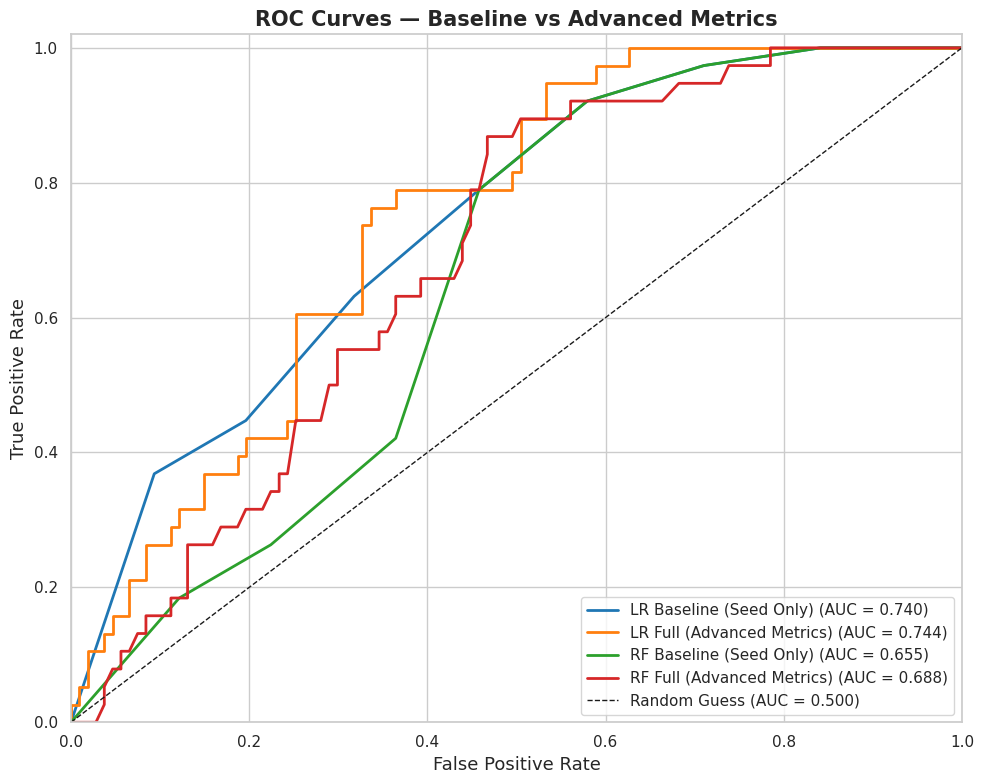

In [8]:
# ============================================================
# ROC CURVES — All 4 Models
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for (name, (model, X_test_data)), color in zip(models.items(), colors):
    y_prob = model.predict_proba(X_test_data)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC = {auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Guess (AUC = 0.500)')
ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate', fontsize=13)
ax.set_title('ROC Curves — Baseline vs Advanced Metrics', fontsize=15, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.show()

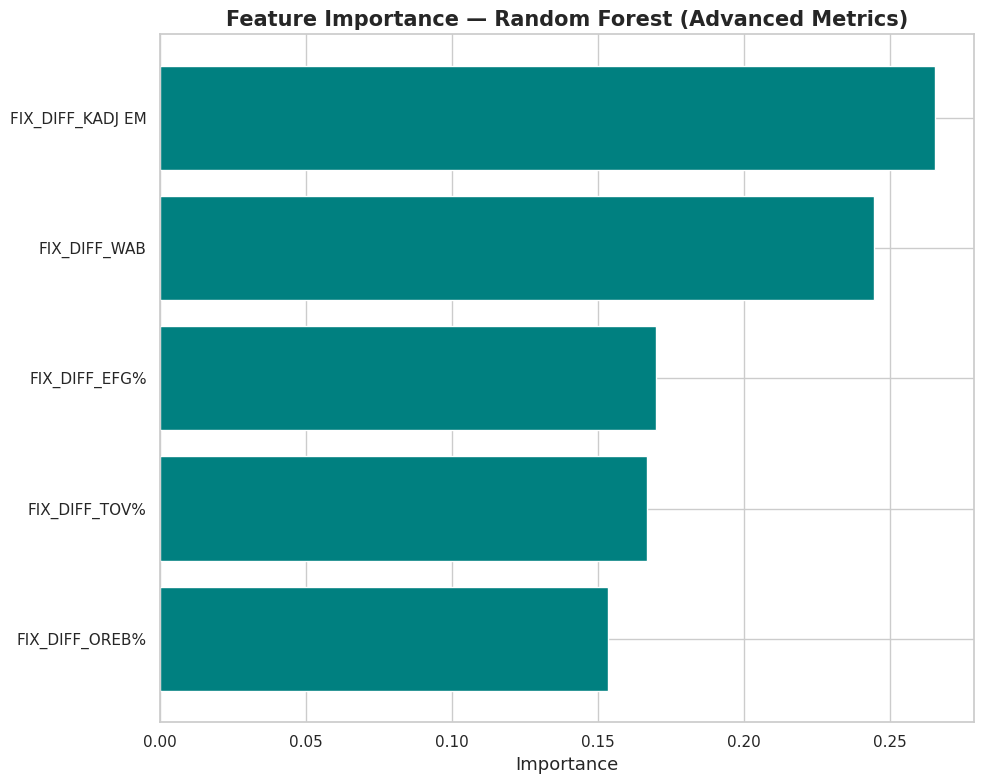


--- Top 5 Most Important Features ---
         Feature  Importance
FIX_DIFF_KADJ EM    0.265453
    FIX_DIFF_WAB    0.244655
   FIX_DIFF_EFG%    0.169710
   FIX_DIFF_TOV%    0.166678
  FIX_DIFF_OREB%    0.153504


In [9]:
# ============================================================
# FEATURE IMPORTANCE — Random Forest (Full Model)
# ============================================================

importances = rf_full.feature_importances_
feat_imp = pd.DataFrame({
    'Feature': fix_diff_cols,
    'Importance': importances
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(feat_imp['Feature'], feat_imp['Importance'], color='teal', edgecolor='white')
ax.set_xlabel('Importance', fontsize=13)
ax.set_title('Feature Importance — Random Forest (Advanced Metrics)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n--- Top 5 Most Important Features ---")
print(feat_imp.sort_values('Importance', ascending=False).head().to_string(index=False))

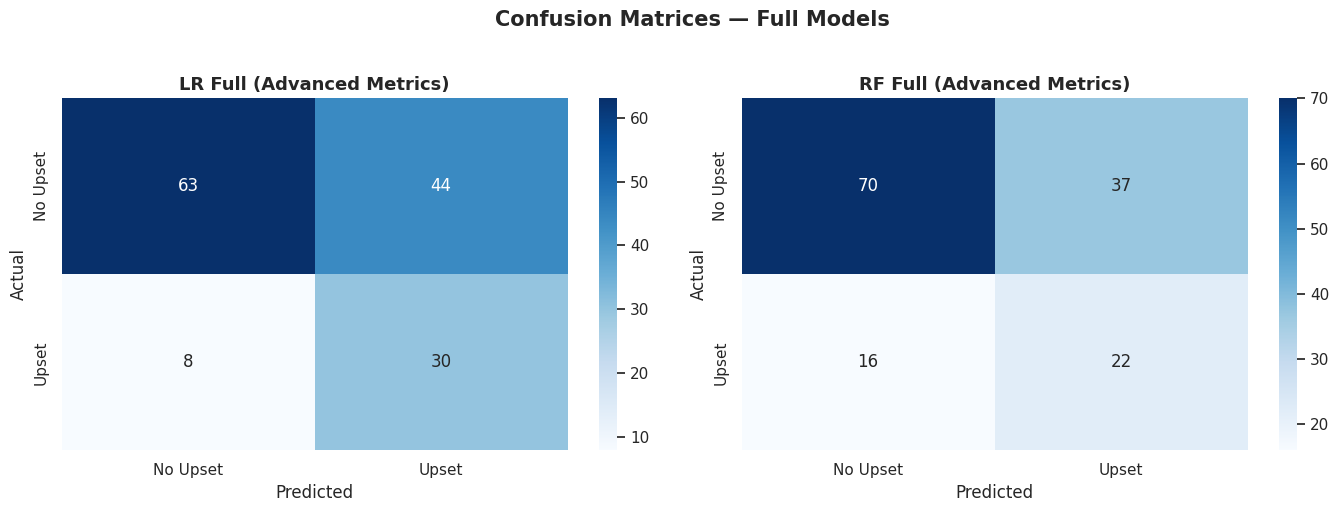


--- Logistic Regression (Full) ---
              precision    recall  f1-score   support

    No Upset       0.89      0.59      0.71       107
       Upset       0.41      0.79      0.54        38

    accuracy                           0.64       145
   macro avg       0.65      0.69      0.62       145
weighted avg       0.76      0.64      0.66       145


--- Random Forest (Full) ---
              precision    recall  f1-score   support

    No Upset       0.81      0.65      0.73       107
       Upset       0.37      0.58      0.45        38

    accuracy                           0.63       145
   macro avg       0.59      0.62      0.59       145
weighted avg       0.70      0.63      0.65       145



In [10]:
# ============================================================
# CONFUSION MATRICES — Best LR vs Best RF
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, (model, X_test_data)) in zip(axes, [
    ('LR Full (Advanced Metrics)', (lr_full, X_full_test_sc)),
    ('RF Full (Advanced Metrics)', (rf_full, X_full_test_sc))
]):
    y_pred = model.predict(X_test_data)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Upset', 'Upset'],
                yticklabels=['No Upset', 'Upset'])
    ax.set_xlabel('Predicted', fontsize=12)
    ax.set_ylabel('Actual', fontsize=12)
    ax.set_title(name, fontsize=13, fontweight='bold')

plt.suptitle('Confusion Matrices — Full Models', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print classification reports
for name, (model, X_test_data) in [
    ('Logistic Regression (Full)', (lr_full, X_full_test_sc)),
    ('Random Forest (Full)', (rf_full, X_full_test_sc))
]:
    y_pred = model.predict(X_test_data)
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred, target_names=['No Upset', 'Upset']))

In [18]:
# ============================================================
# 5-FOLD CROSS-VALIDATION — Confirm Stability
# ============================================================

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=" * 60)
print("5-FOLD CROSS-VALIDATION RESULTS (AUC-ROC)")
print("=" * 60)

cv_models = {
    'LR Baseline': (LogisticRegression(random_state=42, max_iter=1000), X_base, y),
    'LR Full': (LogisticRegression(random_state=42, max_iter=1000), X_full, y),
    'RF Baseline': (RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'), X_base, y),
    'RF Full': (RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'), X_full, y),
}

for name, (model, X_data, y_data) in cv_models.items():
    scores = cross_val_score(model, X_data, y_data, cv=cv, scoring='roc_auc')
    print(f"  {name:<15s} | Mean AUC: {scores.mean():.4f} | Std: {scores.std():.4f} | Folds: {scores.round(4)}")

print("=" * 60)
print("\n✅ If Std < 0.05, your model is stable across folds.")
print("   If Full >> Baseline, advanced metrics add real value.")

5-FOLD CROSS-VALIDATION RESULTS (AUC-ROC)
  LR Baseline     | Mean AUC: 0.7238 | Std: 0.0500 | Folds: [0.6734 0.7721 0.7275 0.7847 0.6614]
  LR Full         | Mean AUC: 0.7518 | Std: 0.0664 | Folds: [0.6915 0.8357 0.7742 0.7988 0.6588]
  RF Baseline     | Mean AUC: 0.6875 | Std: 0.0429 | Folds: [0.6389 0.755  0.7169 0.6741 0.6524]
  RF Full         | Mean AUC: 0.6634 | Std: 0.0734 | Folds: [0.5526 0.7436 0.6922 0.7251 0.6033]

✅ If Std < 0.05, your model is stable across folds.
   If Full >> Baseline, advanced metrics add real value.


Cinderella

In [12]:
# ============================================================
# CELL 11 — Cinderella Profile: What do upset winners look like?
# ============================================================

upsets    = df[df['UPSET'] == 1]
no_upsets = df[df['UPSET'] == 0]

print(f"Total games: {len(df)}  |  Upsets: {len(upsets)} ({len(upsets)/len(df)*100:.1f}%)  |  Non-upsets: {len(no_upsets)}")

winner_cols = ['W_KADJ EM', 'W_BADJ EM', 'W_BARTHAG',
               'W_WAB', 'W_EFG%', 'W_EFG%D',
               'W_TOV%', 'W_WIN%', 'W_ELITE SOS']

rename_map = {
    'W_KADJ EM'  : 'KenPom Adj EM',
    'W_BADJ EM'  : 'Bart Adj EM',
    'W_BARTHAG'  : 'Barttorvik',
    'W_WAB'      : 'Wins Above Bubble',
    'W_EFG%'     : 'eFG%',
    'W_EFG%D'    : 'eFG% Defense',
    'W_TOV%'     : 'Turnover Rate',
    'W_WIN%'     : 'Win %',
    'W_ELITE SOS': 'Elite SOS'
}

profile = pd.DataFrame({
    'Cinderella (Upset Winner)' : upsets[winner_cols].mean(),
    'Expected Winner (No Upset)': no_upsets[winner_cols].mean()
}).rename(index=rename_map)

print("\n=== Average Stats: Cinderella vs. Expected Winner ===")
print(profile.round(3).to_string())

Total games: 578  |  Upsets: 153 (26.5%)  |  Non-upsets: 425

=== Average Stats: Cinderella vs. Expected Winner ===
                   Cinderella (Upset Winner)  Expected Winner (No Upset)
KenPom Adj EM                         13.637                      23.313
Bart Adj EM                           13.365                      23.079
Barttorvik                             0.802                       0.919
Wins Above Bubble                      0.332                       5.700
eFG%                                  51.693                      53.009
eFG% Defense                          47.781                      46.807
Turnover Rate                         17.876                      17.048
Win %                                 69.754                      77.813
Elite SOS                             23.150                      30.365


UPSET RATE BY SEED MATCHUP (Round of 64, 2008-2026)
Matchup       Total Games   Upsets   Upset Rate
-----------------------------------------------------------------
1 vs 16                74        2         2.7%
2 vs 15                71        7         9.9%
3 vs 14                72        8        11.1%
4 vs 13                72       15        20.8%
5 vs 12                72       28        38.9%
6 vs 11                74       33        44.6%
7 vs 10                71       27        38.0%
8 vs 9                 72       33        45.8%


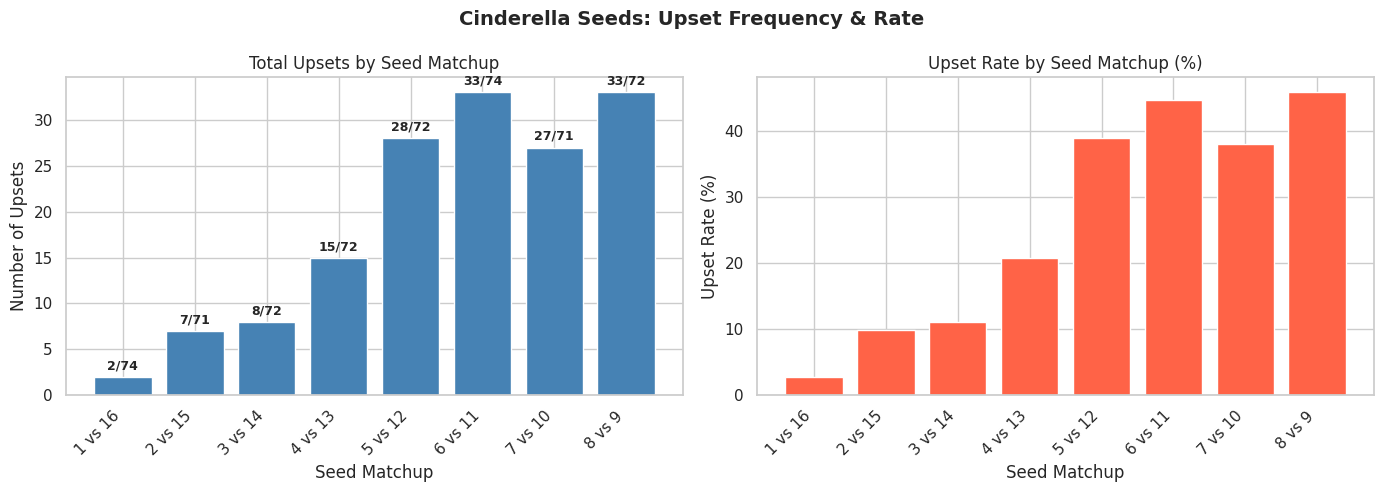

In [13]:
# ============================================================
# CELL 12 — Upset Rate by Seed Matchup (with Denominator)
# ============================================================

# Identify favorite and cinderella in each game
df['FAV_SEED_MATCH'] = df[['WINNER_SEED', 'LOSER_SEED']].min(axis=1)
df['CIN_SEED_MATCH'] = df[['WINNER_SEED', 'LOSER_SEED']].max(axis=1)

# Calculate actual upset rate per matchup
matchup_stats = df.groupby(['FAV_SEED_MATCH', 'CIN_SEED_MATCH']).agg(
    Total_Games=('UPSET', 'count'),
    Upsets=('UPSET', 'sum')
).reset_index()

matchup_stats['Upset_Rate'] = (matchup_stats['Upsets'] / matchup_stats['Total_Games'] * 100).round(1)
matchup_stats['Matchup'] = matchup_stats['FAV_SEED_MATCH'].astype(str) + ' vs ' + matchup_stats['CIN_SEED_MATCH'].astype(str)
matchup_stats = matchup_stats.sort_values('FAV_SEED_MATCH')

print("=" * 65)
print("UPSET RATE BY SEED MATCHUP (Round of 64, 2008-2026)")
print("=" * 65)
print(f"{'Matchup':<12} {'Total Games':>12} {'Upsets':>8} {'Upset Rate':>12}")
print("-" * 65)
for _, row in matchup_stats.iterrows():
    print(f"{row['Matchup']:<12} {int(row['Total_Games']):>12} {int(row['Upsets']):>8} {row['Upset_Rate']:>11.1f}%")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Cinderella Seeds: Upset Frequency & Rate', fontsize=14, fontweight='bold')

axes[0].bar(matchup_stats['Matchup'], matchup_stats['Upsets'],
            color='steelblue', edgecolor='white')
axes[0].set_title('Total Upsets by Seed Matchup')
axes[0].set_xlabel('Seed Matchup')
axes[0].set_ylabel('Number of Upsets')
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45, ha='right')

# Add count labels on bars
for bar, (_, row) in zip(axes[0].patches, matchup_stats.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f"{int(row['Upsets'])}/{int(row['Total_Games'])}",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

axes[1].bar(matchup_stats['Matchup'], matchup_stats['Upset_Rate'],
            color='tomato', edgecolor='white')
axes[1].set_title('Upset Rate by Seed Matchup (%)')
axes[1].set_xlabel('Seed Matchup')
axes[1].set_ylabel('Upset Rate (%)')
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# CELL 13 — Cinderella Score: Rank Every Game in History
# ============================================================

# Use the leakage-free FIX_DIFF_ features (created in Cell 3)
cin_features = ['FIX_DIFF_WAB', 'FIX_DIFF_KADJ EM', 'FIX_DIFF_EFG%',
                'FIX_DIFF_TOV%', 'FIX_DIFF_OREB%']

cin_scaler = StandardScaler()
X_cin = cin_scaler.fit_transform(df[cin_features])

rf_cin = RandomForestClassifier(n_estimators=200, random_state=42)
rf_cin.fit(X_cin, df['UPSET'])

df['CINDERELLA_SCORE'] = rf_cin.predict_proba(X_cin)[:, 1]

cols = ['YEAR', 'WINNER_TEAM', 'WINNER_SEED', 'LOSER_TEAM', 'LOSER_SEED', 'CINDERELLA_SCORE']

# Top Cinderella moments — upsets the model saw coming
true_cinderellas = df[df['UPSET']==1].sort_values('CINDERELLA_SCORE', ascending=False)
print("=== TOP 15 CINDERELLA MOMENTS (Actual Upsets, Ranked by Model Score) ===")
print(true_cinderellas[cols].head(15).to_string(index=False))

# Upsets the model missed — true chaos
missed = df[df['UPSET']==1].sort_values('CINDERELLA_SCORE', ascending=True)
print("\n=== TOP 10 UPSETS THE MODEL DIDN'T SEE COMING ===")
print(missed[cols].head(10).to_string(index=False))

# Near misses — model flagged upset potential but favorite survived
false_alarms = df[df['UPSET']==0].sort_values('CINDERELLA_SCORE', ascending=False)
print("\n=== TOP 10 'NEAR MISS' UPSETS (Model Said Watch Out, But Favorite Won) ===")
print(false_alarms[cols].head(10).to_string(index=False))

=== TOP 15 CINDERELLA MOMENTS (Actual Upsets, Ranked by Model Score) ===
 YEAR  WINNER_TEAM  WINNER_SEED      LOSER_TEAM  LOSER_SEED  CINDERELLA_SCORE
 2021      Rutgers           10         Clemson           7             0.950
 2014    Tennessee           11   Massachusetts           6             0.915
 2008     Davidson           10         Gonzaga           7             0.910
 2012     Colorado           11            UNLV           6             0.905
 2017  Wichita St.           10          Dayton           7             0.895
 2008    Texas A&M            9             BYU           8             0.890
 2018  Florida St.            9        Missouri           8             0.885
 2010 Saint Mary's           10        Richmond           7             0.885
 2014   Pittsburgh            9        Colorado           8             0.885
 2016     Syracuse           10          Dayton           7             0.880
 2016  Wichita St.           11         Arizona           6          

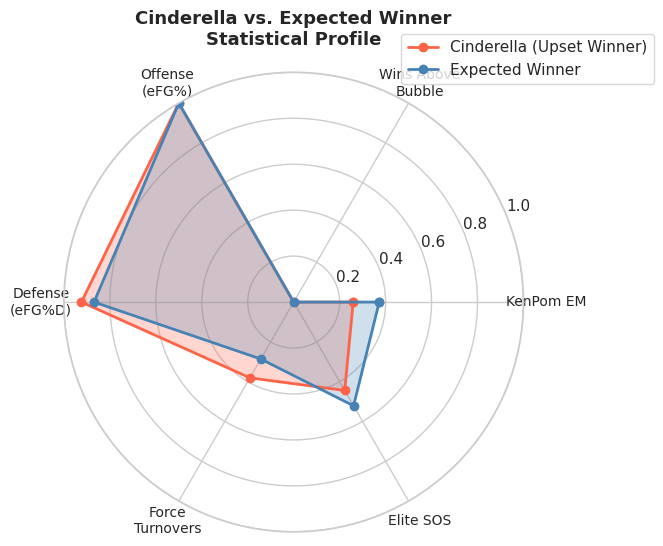

In [15]:
# ============================================================
# CELL 14 — Cinderella Radar Chart
# ============================================================
from sklearn.preprocessing import MinMaxScaler

radar_cols = ['W_KADJ EM', 'W_WAB', 'W_EFG%',
              'W_EFG%D', 'W_TOV%D', 'W_ELITE SOS']
labels = ['KenPom EM', 'Wins Above\nBubble', 'Offense\n(eFG%)',
          'Defense\n(eFG%D)', 'Force\nTurnovers', 'Elite SOS']

cinderella_avg = upsets[radar_cols].mean().values
expected_avg   = no_upsets[radar_cols].mean().values

mm_scaler = MinMaxScaler()
combined = np.vstack([cinderella_avg, expected_avg])
combined_scaled = mm_scaler.fit_transform(combined.T).T
cinderella_scaled = combined_scaled[0]
expected_scaled   = combined_scaled[1]

N = len(labels)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

cinderella_vals = cinderella_scaled.tolist() + cinderella_scaled[:1].tolist()
expected_vals   = expected_scaled.tolist()   + expected_scaled[:1].tolist()

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.plot(angles, cinderella_vals, 'o-', color='tomato',    linewidth=2, label='Cinderella (Upset Winner)')
ax.fill(angles, cinderella_vals, alpha=0.25, color='tomato')
ax.plot(angles, expected_vals,   'o-', color='steelblue', linewidth=2, label='Expected Winner')
ax.fill(angles, expected_vals, alpha=0.25, color='steelblue')

ax.set_thetagrids(np.degrees(angles[:-1]), labels, fontsize=10)
ax.set_ylim(0, 1)
ax.set_title('Cinderella vs. Expected Winner\nStatistical Profile',
             fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

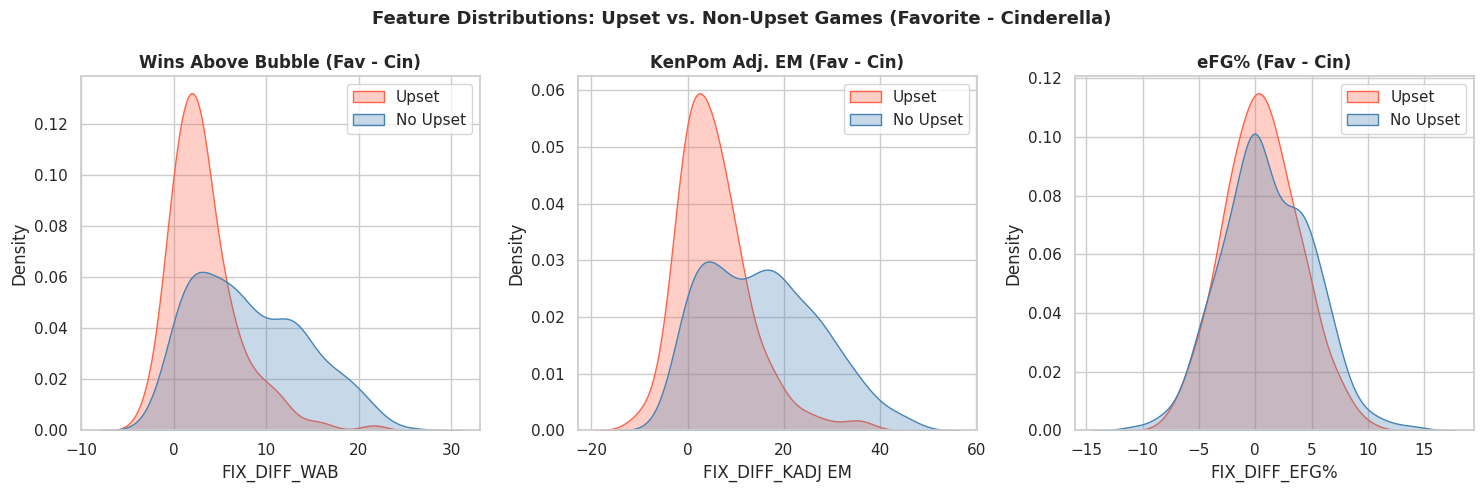

In [16]:
# ============================================================
# CELL 15 — Feature Distributions: Upset vs. Non-Upset
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Feature Distributions: Upset vs. Non-Upset Games (Favorite - Cinderella)',
             fontsize=13, fontweight='bold')

plot_pairs = [
    ('FIX_DIFF_WAB',     'Wins Above Bubble (Fav - Cin)'),
    ('FIX_DIFF_KADJ EM', 'KenPom Adj. EM (Fav - Cin)'),
    ('FIX_DIFF_EFG%',    'eFG% (Fav - Cin)')
]

for ax, (col, title) in zip(axes, plot_pairs):
    sns.kdeplot(upsets[col],    ax=ax, label='Upset',      color='tomato',    fill=True, alpha=0.3)
    sns.kdeplot(no_upsets[col], ax=ax, label='No Upset',   color='steelblue', fill=True, alpha=0.3)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(col)
    ax.legend()

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# CELL 16 — Interactive Upset Prediction Tool
# Uses the trained lr_full model from Cell 5 (leakage-free)
# ============================================================
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Compute seed-level averages for auto-fill defaults
seed_avgs_kadjem = df.groupby('WINNER_SEED')['W_KADJ EM'].mean().to_dict()
seed_avgs_wab    = df.groupby('WINNER_SEED')['W_WAB'].mean().to_dict()
seed_avgs_efg    = df.groupby('WINNER_SEED')['W_EFG%'].mean().to_dict()
seed_avgs_tov    = df.groupby('WINNER_SEED')['W_TOV%'].mean().to_dict()
seed_avgs_oreb   = df.groupby('WINNER_SEED')['W_OREB%'].mean().to_dict()

print("✅ Prediction tool ready! Adjust the sliders and click Predict.")

# --- Widget layout ---
style  = {'description_width': '160px'}
layout = widgets.Layout(width='320px')

header1 = widgets.HTML("<h3 style='color:steelblue'>🏀 Higher Seed (Favorite)</h3>")
header2 = widgets.HTML("<h3 style='color:tomato'>🔥 Lower Seed (Potential Cinderella)</h3>")

fav_name = widgets.Text(description='Team Name:', style=style, layout=layout, placeholder='e.g. Duke')
fav_seed = widgets.IntSlider(description='Seed:', style=style, layout=layout, min=1, max=16, value=1)
fav_kp   = widgets.FloatText(description='KenPom EM:', style=style, layout=layout,
                              value=round(seed_avgs_kadjem.get(1, 28.0), 1))
fav_wab  = widgets.FloatText(description='WAB:', style=style, layout=layout,
                              value=round(seed_avgs_wab.get(1, 12.0), 1))
fav_efg  = widgets.FloatText(description='eFG%:', style=style, layout=layout,
                              value=round(seed_avgs_efg.get(1, 54.0), 1))
fav_tov  = widgets.FloatText(description='TOV%:', style=style, layout=layout,
                              value=round(seed_avgs_tov.get(1, 17.0), 1))
fav_oreb = widgets.FloatText(description='OREB%:', style=style, layout=layout,
                              value=round(seed_avgs_oreb.get(1, 33.0), 1))

cin_name = widgets.Text(description='Team Name:', style=style, layout=layout, placeholder='e.g. Loyola Chicago')
cin_seed = widgets.IntSlider(description='Seed:', style=style, layout=layout, min=1, max=16, value=12)
cin_kp   = widgets.FloatText(description='KenPom EM:', style=style, layout=layout,
                              value=round(seed_avgs_kadjem.get(12, 13.0), 1))
cin_wab  = widgets.FloatText(description='WAB:', style=style, layout=layout,
                              value=round(seed_avgs_wab.get(12, 0.7), 1))
cin_efg  = widgets.FloatText(description='eFG%:', style=style, layout=layout,
                              value=round(seed_avgs_efg.get(12, 50.0), 1))
cin_tov  = widgets.FloatText(description='TOV%:', style=style, layout=layout,
                              value=round(seed_avgs_tov.get(12, 18.0), 1))
cin_oreb = widgets.FloatText(description='OREB%:', style=style, layout=layout,
                              value=round(seed_avgs_oreb.get(12, 31.0), 1))

# Auto-update defaults when seed slider changes
def update_fav_defaults(change):
    s = fav_seed.value
    fav_kp.value   = round(seed_avgs_kadjem.get(s, 20.0), 1)
    fav_wab.value  = round(seed_avgs_wab.get(s, 3.0), 1)
    fav_efg.value  = round(seed_avgs_efg.get(s, 52.0), 1)
    fav_tov.value  = round(seed_avgs_tov.get(s, 17.5), 1)
    fav_oreb.value = round(seed_avgs_oreb.get(s, 33.0), 1)

def update_cin_defaults(change):
    s = cin_seed.value
    cin_kp.value   = round(seed_avgs_kadjem.get(s, 13.0), 1)
    cin_wab.value  = round(seed_avgs_wab.get(s, 0.5), 1)
    cin_efg.value  = round(seed_avgs_efg.get(s, 50.0), 1)
    cin_tov.value  = round(seed_avgs_tov.get(s, 18.0), 1)
    cin_oreb.value = round(seed_avgs_oreb.get(s, 31.0), 1)

fav_seed.observe(update_fav_defaults, names='value')
cin_seed.observe(update_cin_defaults, names='value')

predict_btn = widgets.Button(description='🎯 Predict Upset Probability',
                              button_style='primary',
                              layout=widgets.Layout(width='300px', height='40px'))
output = widgets.Output()

# --- Prediction logic ---
def on_predict(b):
    with output:
        clear_output()

        # Compute diffs as FAVORITE - CINDERELLA (same as training)
        diff_wab  = fav_wab.value  - cin_wab.value
        diff_kp   = fav_kp.value   - cin_kp.value
        diff_efg  = fav_efg.value  - cin_efg.value
        diff_tov  = fav_tov.value  - cin_tov.value
        diff_oreb = fav_oreb.value - cin_oreb.value

        # Match the feature order from Cell 3:
        # ['FIX_DIFF_WAB', 'FIX_DIFF_KADJ EM', 'FIX_DIFF_EFG%', 'FIX_DIFF_TOV%', 'FIX_DIFF_OREB%']
        X_input = np.array([[diff_wab, diff_kp, diff_efg, diff_tov, diff_oreb]])

        # Use scaler_full and lr_full from Cell 5
        prob_upset   = lr_full.predict_proba(scaler_full.transform(X_input))[0][1]
        prob_noupset = 1 - prob_upset

        if prob_upset >= 0.75:
            tier, color = "🚨 HIGH CINDERELLA ALERT", "tomato"
        elif prob_upset >= 0.50:
            tier, color = "⚠️ UPSET LIKELY", "orange"
        elif prob_upset >= 0.30:
            tier, color = "👀 WATCH OUT", "goldenrod"
        else:
            tier, color = "✅ FAVORITE HOLDS", "steelblue"

        fav_label = fav_name.value if fav_name.value else f"#{fav_seed.value} Seed"
        cin_label = cin_name.value if cin_name.value else f"#{cin_seed.value} Seed"

        display(HTML(f"""
        <div style='border:2px solid {color}; border-radius:10px; padding:20px; max-width:500px;'>
            <h2 style='color:{color}; text-align:center;'>{tier}</h2>
            <hr/>
            <p style='font-size:16px;'>
                <b>{cin_label} (#{cin_seed.value})</b> upsets
                <b>{fav_label} (#{fav_seed.value})</b>
            </p>
            <p style='font-size:22px; text-align:center;'>
                Upset Probability: <b style='color:{color};'>{prob_upset:.1%}</b>
            </p>
            <p style='font-size:16px; text-align:center;'>
                Favorite wins: {prob_noupset:.1%}
            </p>
            <hr/>
            <b>Key Differentials (Favorite − Cinderella):</b><br/>
            WAB: {diff_wab:+.1f} &nbsp;|&nbsp;
            KenPom EM: {diff_kp:+.1f} &nbsp;|&nbsp;
            eFG%: {diff_efg:+.1f} &nbsp;|&nbsp;
            TOV%: {diff_tov:+.1f} &nbsp;|&nbsp;
            OREB%: {diff_oreb:+.1f}
        </div>
        """))

predict_btn.on_click(on_predict)

# --- Display ---
left_col  = widgets.VBox([header1, fav_name, fav_seed, fav_kp, fav_wab, fav_efg, fav_tov, fav_oreb])
right_col = widgets.VBox([header2, cin_name, cin_seed, cin_kp, cin_wab, cin_efg, cin_tov, cin_oreb])
ui = widgets.HBox([left_col, right_col])

display(ui, predict_btn, output)

✅ Prediction tool ready! Adjust the sliders and click Predict.


Button(button_style='primary', description='🎯 Predict Upset Probability', layout=Layout(height='40px', width='…

Output()